# 0. Overview

`shfm` plans paths for a forklift with two independently steered axles. It
returns a globally optimal path in the extended configuration space
$(x, y, \theta, s)$, where $s$ is the operational mode of the vehicle.

Such a vehicle can crab sideways and turn on a much tighter radius than a car.
A planner that ignores these motions misses the shorter paths they allow; a
planner that exposes all of them uses crab motion everywhere, including along
open corridors, where it brings no advantage and is hard to read for anyone
working nearby. We keep both behaviours available and assign a cost to each
change of mode, so manoeuvring is reserved for the places whose geometry
demands it. The switching is part of the optimisation, not a post-processing
pass, so the result stays optimal for the cost that was posed.

The notebooks of this series document the package. They accompany the PhD
thesis of Julien Pascal, presented in the README, and cite its equations and
figures by number. In this notebook, we run one solve, list the notebooks, and
state the solver library and the units that all of them use.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from shfm import DEFAULT_VEHICLE
from shfm.figures import save

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

from shfm import from_image, Planner, REFERENCE_COEFFICIENTS
from shfm.kinematics import control_set
from shfm.plotting import draw_map, draw_path, draw_footprints, draw_pose
from shfm.solver import agd_location

## In one solve

We consider a forklift backing into a bay barely longer than itself, 4.4 m
against 3.65 m, on a 100 by 150 grid where the vehicle spans 73 units.
The solve uses the transition costs of the parameter study, $k_1 = 10$,
$k_2 = 50$, and starts in forward navigation; notebooks 4 and 5 solve the same
problem at the settings of the comparisons.

solved in 1.3 s


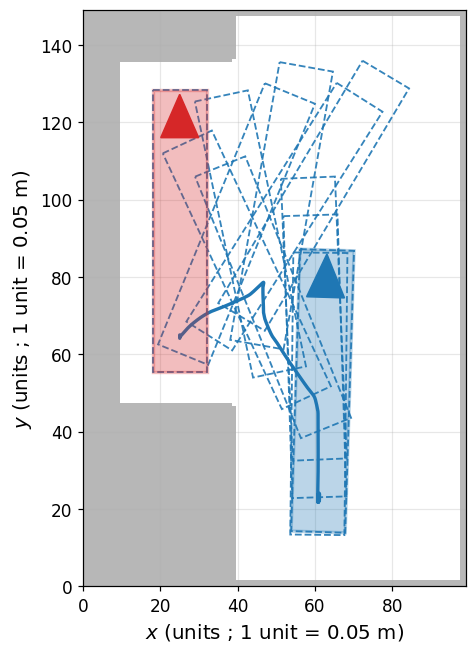

In [2]:
env = from_image("../data/maps/docking.png", (100, 150), zoom=20, n_theta=100,
                 name="slot")
mk = lambda th, wb, xp: control_set(th, wb, xp=xp, delta_f_max=1.05,
                                    delta_r_max=1.05, **REFERENCE_COEFFICIENTS)

import time
t0 = time.time()
result = Planner(env, k1=10, k2=50, controls=mk).solve(
    seed=[60, 20, np.pi / 2, 0], tips=[[25, 65, np.pi / 2, 0]])
print("solved in %.1f s" % (time.time() - t0))

g = result.path(0)
fig, ax = plt.subplots(figsize=(5.2, 6.8))
draw_map(ax, env)
draw_path(ax, g, color="tab:blue")
draw_footprints(ax, g, env.vehicle, env.zoom, n=12, color="tab:blue")
draw_pose(ax, g[0, 0], g[0, 1], g[0, 2], env.vehicle, env.zoom, "tab:blue")
draw_pose(ax, g[-1, 0], g[-1, 1], g[-1, 2], env.vehicle, env.zoom, "tab:red")
save(fig, "00_overview"); plt.show()

## The notebooks

| | | |
|---|---|---|
| 1 | [Vehicle and kinematics](01_vehicle_and_kinematics.ipynb) | the 4WS model, its modes, Tissot's indicatrix, the turning radius |
| 2 | [Collision and configuration space](02_collision_and_configuration_space.ipynb) | the disc covering, the lift from the plane to $(x, y, \theta)$ |
| 3 | [Hamiltonian Fast Marching](03_hamiltonian_fast_marching.ipynb) | the value function, geodesic extraction, the obstacle cost |
| 4 | [The state system](04_state_system.ipynb) | the four modes, transition costs, the extended equation |
| 5 | [Precision docking and narrow passages](05_precision_docking.ipynb) | the docking slot and the narrow passage, two axles against one |
| 6 | [Discretisation and parameters](06_parameter_study.ipynb) | the grid, then what each of the six parameters controls |
| 7 | [Benchmarks](07_benchmarks.ipynb) | comparison against sampling-based planners |
| 8 | [Benchmark metrics](08_benchmark_metrics.ipynb) | the violins, the table, and how the solver scales |
| 9 | [The scheme, step by step](09_scheme_step_by_step.ipynb) | the adaptive stencil and one update, by hand |

The examples under `examples/` stand apart from this sequence:
[`hello_world.py`](../examples/hello_world.py), the shortest program that
plans a path, and [`your_own_problem.ipynb`](../examples/your_own_problem.ipynb),
the planner applied to a problem of your own.

## Before running anything

**The solver library is vendored.** `agd` provides the anisotropic eikonal
solver; the copy under `external/agd` is the one this work was developed
against, and it is put ahead of any installed copy: an installed release may
not carry the `geodesic_mixed_state` option (agd 0.2.4 does not), without
which the mode column of a path is interpolated between modes, or the path
stops at the first change of mode.

In [3]:
print("agd in use:", os.path.relpath(agd_location(), ".."))

agd in use: external/agd/agd


**Units.** The vehicle is 3.649 m long. `zoom` is the number of grid units
per metre, so at `zoom=4` the vehicle spans 14.6 units and one unit is 25 cm.
Lengths, curvatures
and clearances are reported in grid units; only the swept floor area is in
square metres, so that it can be read against the vehicle's own footprint of
2.55 square metres. The scene above runs at `zoom=20`: one unit is 5 cm and the
vehicle spans 73 units.

In [4]:
print("one unit        = %.3g m" % env.metres_per_unit())
print("vehicle spans   = %.0f units" % (env.vehicle.length * env.zoom))
print("footprint area  = %.2f m2" % env.vehicle.footprint_area())

one unit        = 0.05 m
vehicle spans   = 73 units
footprint area  = 2.55 m2


---

Next: [1. The vehicle and its kinematics](01_vehicle_and_kinematics.ipynb)